load data and define the model registry

In [3]:
import numpy as np, pandas as pd, json
from pathlib import Path
from sklearn.metrics import r2_score, mean_absolute_error
from scipy.stats import spearmanr
import matplotlib.pyplot as plt

ROOT = Path(r"D:\Pancreatic_GraphTCDR")
T = ROOT / "data" / "processed" / "target_v2"
RES = ROOT / "results" / "v2"

train = pd.read_csv(T / "train_v2.csv")
test = pd.read_csv(T / "test_v2.csv")
assert len(test) == 3802

# model name -> filename pattern ({s} = seed)
REG = {
    "RF + PCA":                  "pred_rf_pca_s{s}.csv",
    "RF + AE":                   "pred_rf_ae_s{s}.csv",
    "RF + AE (quality wt)":      "pred_rf_ae_qual_s{s}.csv",
    "RF + AE (tail wt)":         "pred_rf_ae_tail_s{s}.csv",
    "RF + AE (LDS wt)":          "pred_rf_ae_lds_s{s}.csv",
    "RF + AE (LDS+quality wt)":  "pred_rf_ae_ldsq_s{s}.csv",
    "RF + AE (tail+quality wt)": "pred_rf_ae_both_s{s}.csv",
    "XGBoost + PCA":             "pred_xgb_pca_s{s}.csv",
    "XGBoost + AE":              "pred_xgb_ae_s{s}.csv",
    "MLP + PCA":                 "pred_mlp_pca_s{s}.csv",
    "MLP + AE":                  "pred_mlp_ae_s{s}.csv",
    "CNN + PCA":                 "pred_cnn_pca_s{s}.csv",
    "CNN + AE":                  "pred_cnn_ae_s{s}.csv",
    "CNN + AE (quality wt)":     "pred_cnn_ae_qual_s{s}.csv",
    "Graph A (Pearson, no resp. edges)": "pred_graph_A_s{s}.csv",
    "Graph B (resp. edges, half data)":  "pred_graph_B_s{s}.csv",
    "Graph A + residual":        "pred_graph_A_res_s{s}.csv",
    "Graph A + residual, 16 heads": "pred_graph_A_res16_s{s}.csv",
    "Graph A + residual + kNN drug graph": "pred_graph_A_res_knn_s{s}.csv",
    "RF + AE (pan-cancer training)": "pred_rf_ae_pancancer_s{s}.csv",
}
SEEDS = [42, 43, 44]

masks = {"full": np.ones(len(test), bool),
         "core": (test["y_raw"].abs() <= 3).values,
         "hq": test["hq_r2"].values.astype(bool),
         "extreme": test["extreme_abs3"].values.astype(bool)}
print({k: int(m.sum()) for k, m in masks.items()})   # expect 3802, 3743, 1936, 59

def sc(y, p):
    return dict(MAE=mean_absolute_error(y, p), RMSE=float(np.sqrt(np.mean((y - p) ** 2))),
                R2=r2_score(y, p), rho=spearmanr(y, p)[0] if np.std(p) > 0 else np.nan)

{'full': 3802, 'core': 3743, 'hq': 1936, 'extreme': 59}


score everything (per seed, then mean and SD)

In [4]:
# floor predictors, means from TRAIN only
gm = train["y_clip"].mean()
cm = train.groupby("omics_index")["y_clip"].mean()
FLOOR = {"Floor: global mean": np.full(len(test), gm),
         "Floor: cell-line mean": test["omics_index"].map(cm).fillna(gm).values}

PRED = {}   # name -> list of per-seed prediction arrays
for name, arr in FLOOR.items():
    PRED[name] = [arr]
missing = []
for name, pat in REG.items():
    ps = []
    for s in SEEDS:
        f = RES / pat.format(s=s)
        if f.exists():
            p = pd.read_csv(f)["pred_clip"].values
            assert len(p) == len(test), f"{f.name}: wrong length"
            ps.append(p)
        else:
            missing.append(f.name)
    if ps: PRED[name] = ps
print("missing files:", missing)

rows = []
for name, ps in PRED.items():
    for tgt in ["y_clip", "y_raw"]:
        y = test[tgt].values
        for k, m in masks.items():
            if m.sum() < 3: continue
            d = pd.DataFrame([sc(y[m], p[m]) for p in ps])
            rows.append({"model": name, "target": tgt, "subset": k, "n": int(m.sum()), "n_seeds": len(ps),
                         **{f"{c}_mean": d[c].mean() for c in d},
                         **{f"{c}_sd": (d[c].std() if len(ps) > 1 else 0.0) for c in d}})
full = pd.DataFrame(rows)
full.to_csv(RES / "FINAL_all_scores.csv", index=False)

# compact headline table: y_clip
h = full[full.target == "y_clip"]
def get(sub, col): return h[h.subset == sub].set_index("model")[col]
main = pd.DataFrame({
    "R2": get("full", "R2_mean"), "R2_sd": get("full", "R2_sd"),
    "MAE": get("full", "MAE_mean"), "RMSE": get("full", "RMSE_mean"),
    "Spearman": get("full", "rho_mean"),
    "R2_core": get("core", "R2_mean"), "R2_hq": get("hq", "R2_mean"),
    "MAE_extreme": get("extreme", "MAE_mean"),
}).sort_values("R2", ascending=False)
main.round(4).to_csv(RES / "FINAL_headline_table_yclip.csv")
print("PRIMARY TARGET: y_clip (test, n=3802; mean over seeds)")
print(main.round(4).to_string())

missing files: []


C:\Users\SREEKUTTY\AppData\Local\Temp\ipykernel_38000\3399250286.py:48: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  R2=r2_score(y, p), rho=spearmanr(y, p)[0] if np.std(p) > 0 else np.nan)
C:\Users\SREEKUTTY\AppData\Local\Temp\ipykernel_38000\3399250286.py:48: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  R2=r2_score(y, p), rho=spearmanr(y, p)[0] if np.std(p) > 0 else np.nan)
C:\Users\SREEKUTTY\AppData\Local\Temp\ipykernel_38000\3399250286.py:48: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  R2=r2_score(y, p), rho=spearmanr(y, p)[0] if np.std(p) > 0 else np.nan)
C:\Users\SREEKUTTY\AppData\Local\Temp\ipykernel_38000\3399250286.py:48: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  R2=r2_score(y, p), rho=spearmanr(y, p)[0] if np.std(p) > 0 else np.nan)
C:\Users\SREEKUTTY\AppData\Local\Temp\ip

PRIMARY TARGET: y_clip (test, n=3802; mean over seeds)
                                         R2   R2_sd     MAE    RMSE  Spearman  R2_core   R2_hq  MAE_extreme
model                                                                                                      
RF + AE (LDS+quality wt)             0.2042  0.0060  0.5290  0.7375    0.4126   0.1966  0.0910       2.2733
RF + AE (tail+quality wt)            0.1969  0.0040  0.5250  0.7409    0.4184   0.1932  0.0593       2.3095
RF + AE (LDS wt)                     0.1943  0.0045  0.5294  0.7421    0.3995   0.1869  0.0787       2.2825
RF + AE (quality wt)                 0.1918  0.0021  0.5210  0.7432    0.4287   0.1894  0.0265       2.3223
RF + AE (tail wt)                    0.1908  0.0051  0.5262  0.7437    0.4082   0.1865  0.0499       2.3152
RF + AE                              0.1816  0.0046  0.5213  0.7479    0.4203   0.1793  0.0080       2.3336
RF + PCA                             0.1675  0.0042  0.5220  0.7543    0.4183   0

secondary target (raw) table

In [5]:
r = full[(full.target == "y_raw")]
def getr(sub, col): return r[r.subset == sub].set_index("model")[col]
raw = pd.DataFrame({"R2_full": getr("full", "R2_mean"), "RMSE_full": getr("full", "RMSE_mean"),
                    "MAE_full": getr("full", "MAE_mean"), "R2_core": getr("core", "R2_mean"),
                    "MAE_extreme": getr("extreme", "MAE_mean")}).sort_values("R2_full", ascending=False)
raw.round(4).to_csv(RES / "FINAL_headline_table_yraw.csv")
print("SECONDARY TARGET: y_raw (predictions trained on y_clip, scored against raw)")
print(raw.round(4).to_string())

SECONDARY TARGET: y_raw (predictions trained on y_clip, scored against raw)
                                     R2_full  RMSE_full  MAE_full  R2_core  MAE_extreme
model                                                                                  
RF + AE (LDS+quality wt)              0.0263     2.2560    0.6156   0.1944       7.7148
RF + AE (tail+quality wt)             0.0261     2.2563    0.6116   0.1913       7.7510
RF + AE (quality wt)                  0.0258     2.2566    0.6076   0.1878       7.7638
RF + AE (LDS wt)                      0.0250     2.2575    0.6160   0.1847       7.7240
RF + AE (tail wt)                     0.0250     2.2576    0.6128   0.1846       7.7567
RF + AE                               0.0248     2.2578    0.6079   0.1779       7.7751
RF + AE (pan-cancer training)         0.0236     2.2592    0.6086   0.1611       7.7550
RF + PCA                              0.0232     2.2596    0.6086   0.1655       7.8000
CNN + AE (quality wt)                 0.0188

3-seed ensembles for the key models

In [6]:
key = ["RF + AE", "RF + AE (tail+quality wt)", "RF + AE (LDS+quality wt)", "CNN + AE", "MLP + AE",
       "Graph A + residual + kNN drug graph"]
ens = []
for name in key:
    if name in PRED and len(PRED[name]) > 1:
        e = np.mean(PRED[name], 0)
        ens.append({"model": name + " [3-seed ensemble]", **sc(test["y_clip"].values, e)})
print(pd.DataFrame(ens).round(4).to_string(index=False))

                                                model    MAE   RMSE     R2    rho
                            RF + AE [3-seed ensemble] 0.5206 0.7473 0.1829 0.4227
          RF + AE (tail+quality wt) [3-seed ensemble] 0.5246 0.7402 0.1982 0.4212
           RF + AE (LDS+quality wt) [3-seed ensemble] 0.5285 0.7368 0.2056 0.4158
                           CNN + AE [3-seed ensemble] 0.5481 0.7687 0.1353 0.3624
                           MLP + AE [3-seed ensemble] 0.5545 0.7749 0.1215 0.3481
Graph A + residual + kNN drug graph [3-seed ensemble] 0.5737 0.8019 0.0590 0.2602


figures (R² leaderboard and per-bin bias)

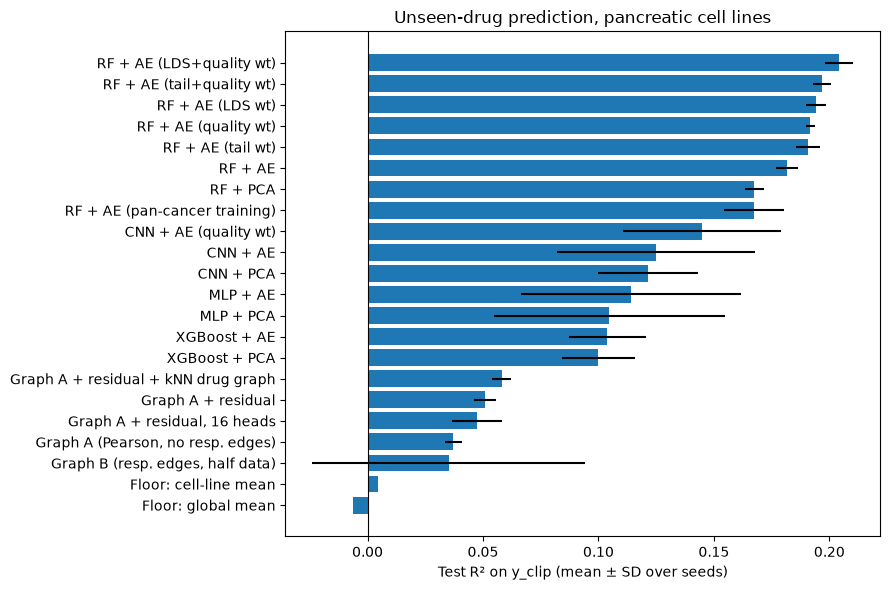

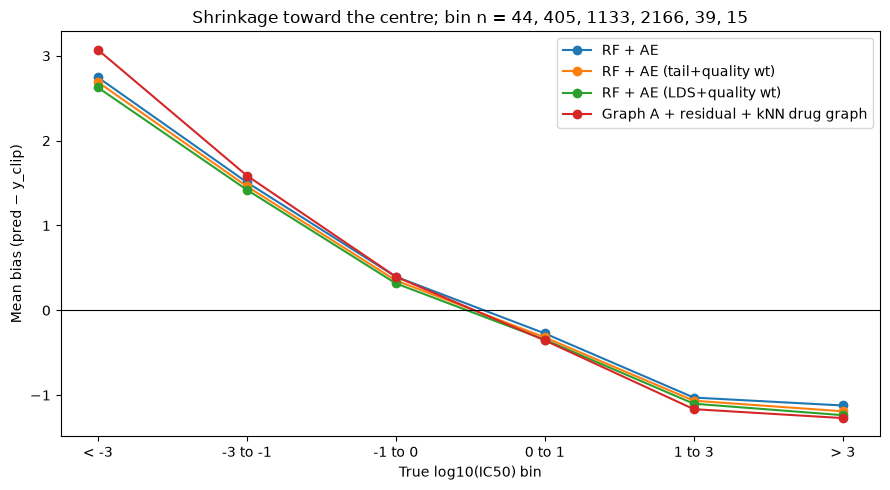

RF + AE: precision 0.308 (random 0.10)
RF + AE (tail+quality wt): precision 0.300 (random 0.10)
CNN + AE: precision 0.308 (random 0.10)
Graph A + residual + kNN drug graph: precision 0.203 (random 0.10)


In [7]:
# Figure 1: leaderboard
m = main.sort_values("R2")
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(m.index, m["R2"], xerr=m["R2_sd"])
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("Test R² on y_clip (mean ± SD over seeds)")
ax.set_title("Unseen-drug prediction, pancreatic cell lines")
plt.tight_layout(); plt.savefig(RES / "fig_leaderboard.png", dpi=200); plt.show()

# Figure 2: bias by response bin (RF unweighted vs tail+quality weighted vs graph kNN)
bins = [-np.inf, -3, -1, 0, 1, 3, np.inf]
labels = ["< -3", "-3 to -1", "-1 to 0", "0 to 1", "1 to 3", "> 3"]
test["bin"] = pd.cut(test["y_raw"], bins=bins, labels=labels, right=False)
fig, ax = plt.subplots(figsize=(9, 5))
for name in ["RF + AE", "RF + AE (tail+quality wt)", "RF + AE (LDS+quality wt)", "Graph A + residual + kNN drug graph"]:
    p = np.mean(PRED[name], 0)
    b = [np.mean(p[(test["bin"] == l).values] - test["y_clip"].values[(test["bin"] == l).values]) for l in labels]
    ax.plot(labels, b, marker="o", label=name)
ax.axhline(0, color="k", lw=0.8)
ax.set_ylabel("Mean bias (pred − y_clip)"); ax.set_xlabel("True log10(IC50) bin")
counts = test["bin"].value_counts().loc[labels].tolist()
ax.set_title("Shrinkage toward the centre; bin n = " + ", ".join(map(str, counts)))
ax.legend(); plt.tight_layout(); plt.savefig(RES / "fig_bias_by_bin.png", dpi=200); plt.show()

# Sensitive-tail enrichment: precision in predicted most-sensitive 10% (random = 0.10)
k = int(0.10 * len(test)); true_low = set(np.argsort(test["y_raw"].values)[:k])
for name in ["RF + AE", "RF + AE (tail+quality wt)", "CNN + AE", "Graph A + residual + kNN drug graph"]:
    if name in PRED:
        p = np.mean(PRED[name], 0)
        print(f"{name}: precision {len(true_low & set(np.argsort(p)[:k])) / k:.3f} (random 0.10)")

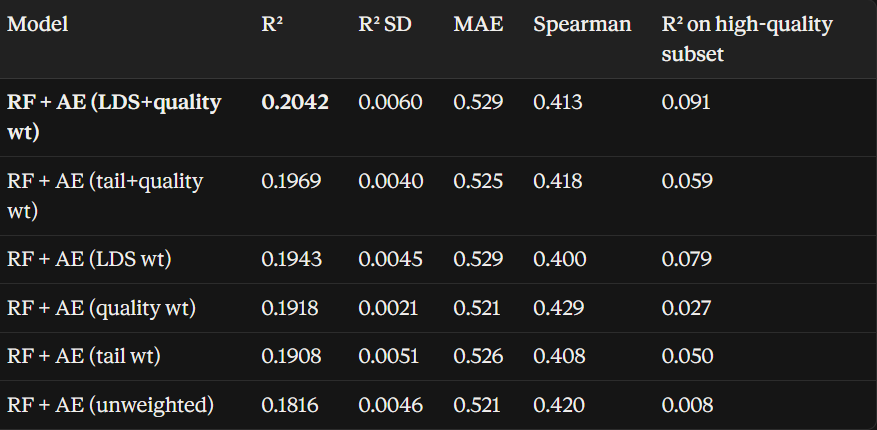

In [8]:
from pathlib import Path
import pandas as pd
P = Path(r"D:\Pancreatic_GraphTCDR\data\processed")
print(sorted(p.name for p in P.glob("*")))

R = Path(r"D:\Pancreatic_GraphTCDR\data")
print([str(p.relative_to(R)) for p in R.rglob("*") if p.is_file() and p.stat().st_size > 5_000_000][:40])

['ae_embeddings_402x512.npy', 'autoencoder_best.pt', 'drug_adjacency_fingerprint_threshold075.npy', 'drug_morgan_fingerprints_1228x2048.npy', 'drug_similarity_fingerprint_threshold075.npy', 'drug_smiles_1228.csv', 'integrated_modeling_table.csv', 'integrated_with_auc.csv', 'pancreatic28_ae_embeddings_512.csv', 'pancreatic28_cell_adjacency_methylation_threshold075.npy', 'pancreatic28_cell_mapping.csv', 'pancreatic28_cell_similarity_methylation.npy', 'pancreatic28_cnv.pt', 'pancreatic28_gene_expression.pt', 'pancreatic28_methylation.pt', 'pancreatic28_mirna.pt', 'results', 'splits', 'target_v2', 'targets_raw_v1.csv', 'train_response_cell_drug_edges_lower50.csv', 'train_response_drug_edge_summary.csv']
['processed\\autoencoder_best.pt', 'processed\\drug_adjacency_fingerprint_threshold075.npy', 'processed\\drug_similarity_fingerprint_threshold075.npy', 'processed\\targets_raw_v1.csv', 'processed\\results\\graphtcdr_baseline_best.pt', 'processed\\results\\graphtcdr_quality_aware_best.pt', '

In [9]:
rng = np.random.default_rng(0)
y = test["y_clip"].values
drug_ids = test["drug_index"].values
ud = np.unique(drug_ids)
idx_by_drug = {d: np.where(drug_ids == d)[0] for d in ud}
B = 1000
samples = [np.concatenate([idx_by_drug[d] for d in rng.choice(ud, len(ud), replace=True)]) for _ in range(B)]

def r2_on(idx, p): return r2_score(y[idx], p[idx])

models = ["RF + AE", "RF + AE (LDS+quality wt)", "RF + AE (tail+quality wt)",
          "RF + AE (pan-cancer training)", "CNN + AE", "MLP + AE", "XGBoost + AE",
          "Graph A + residual + kNN drug graph"]
ens = {m: np.mean(PRED[m], 0) for m in models}        # 3-seed ensembles
boot = {m: np.array([r2_on(ix, ens[m]) for ix in samples]) for m in models}

print("R2 with 95% CI (bootstrap over 246 test drugs, 3-seed ensembles)")
for m in models:
    lo, hi = np.percentile(boot[m], [2.5, 97.5])
    print(f"{m:40s} {r2_on(np.arange(len(y)), ens[m]):.3f}  [{lo:.3f}, {hi:.3f}]")

print("\nPaired difference vs RF + AE (unweighted)")
for m in models[1:]:
    d = boot[m] - boot["RF + AE"]
    lo, hi = np.percentile(d, [2.5, 97.5])
    print(f"{m:40s} diff {d.mean():+.3f}  [{lo:+.3f}, {hi:+.3f}]  P(better)={np.mean(d>0):.2f}")

R2 with 95% CI (bootstrap over 246 test drugs, 3-seed ensembles)
RF + AE                                  0.183  [0.086, 0.278]
RF + AE (LDS+quality wt)                 0.206  [0.112, 0.295]
RF + AE (tail+quality wt)                0.198  [0.103, 0.290]
RF + AE (pan-cancer training)            0.169  [0.055, 0.276]
CNN + AE                                 0.135  [0.079, 0.178]
MLP + AE                                 0.121  [0.066, 0.168]
XGBoost + AE                             0.108  [0.027, 0.171]
Graph A + residual + kNN drug graph      0.059  [-0.006, 0.125]

Paired difference vs RF + AE (unweighted)
RF + AE (LDS+quality wt)                 diff +0.022  [-0.003, +0.043]  P(better)=0.96
RF + AE (tail+quality wt)                diff +0.015  [+0.001, +0.029]  P(better)=0.98
RF + AE (pan-cancer training)            diff -0.014  [-0.034, +0.005]  P(better)=0.07
CNN + AE                                 diff -0.047  [-0.125, +0.022]  P(better)=0.10
MLP + AE                               

decomposition

In [10]:
from scipy.stats import spearmanr, pearsonr
df = test[["drug_index", "omics_index", "y_clip"]].copy()
models = ["Floor: cell-line mean", "RF + AE", "RF + AE (LDS+quality wt)",
          "CNN + AE", "XGBoost + AE", "Graph A + residual + kNN drug graph"]

# how much variance is between drugs vs within drugs (true labels)
dm = df.groupby("drug_index")["y_clip"].transform("mean")
between = np.var(dm) / np.var(df["y_clip"])
print(f"Share of y_clip variance explained by drug identity alone: {between:.2f}")
print("drugs:", df.drug_index.nunique(), "| lines per drug (median):",
      int(df.groupby('drug_index').size().median()), "\n")

rows = []
for m in models:
    df["p"] = np.mean(PRED[m], 0)
    g = df.groupby("drug_index")
    # POTENCY: drug-level mean across lines, compared across the 246 drugs
    dmean = g[["y_clip", "p"]].mean()
    pot_rho = spearmanr(dmean.y_clip, dmean.p)[0] if dmean.p.std() > 0 else np.nan
    # SELECTIVITY: remove each drug's mean, correlate the within-drug deviations
    dy = df.y_clip - g["y_clip"].transform("mean")
    dp = df.p - g["p"].transform("mean")
    sel_pooled = pearsonr(dy, dp)[0] if dp.std() > 0 else np.nan
    # median per-drug Spearman across lines (drugs with >=10 lines and real spread)
    per = []
    for d, s in g:
        if len(s) >= 10 and s.y_clip.std() > 0.05 and s.p.std() > 0:
            per.append(spearmanr(s.y_clip, s.p)[0])
    rows.append({"model": m, "potency_rho": pot_rho, "selectivity_r": sel_pooled,
                 "median_per_drug_rho": np.median(per) if per else np.nan, "n_drugs_used": len(per)})
res = pd.DataFrame(rows).set_index("model")
print(res.round(3).to_string())
res.round(4).to_csv(RES / "decomposition_potency_selectivity.csv")

Share of y_clip variance explained by drug identity alone: 0.76
drugs: 246 | lines per drug (median): 17 

                                     potency_rho  selectivity_r  median_per_drug_rho  n_drugs_used
model                                                                                             
Floor: cell-line mean                      0.128          0.201                0.241           167
RF + AE                                    0.379          0.300                0.329           167
RF + AE (LDS+quality wt)                   0.380          0.297                0.301           167
CNN + AE                                   0.259          0.209                0.250           167
XGBoost + AE                               0.257          0.215                0.268           167
Graph A + residual + kNN drug graph        0.193          0.199                0.221           167


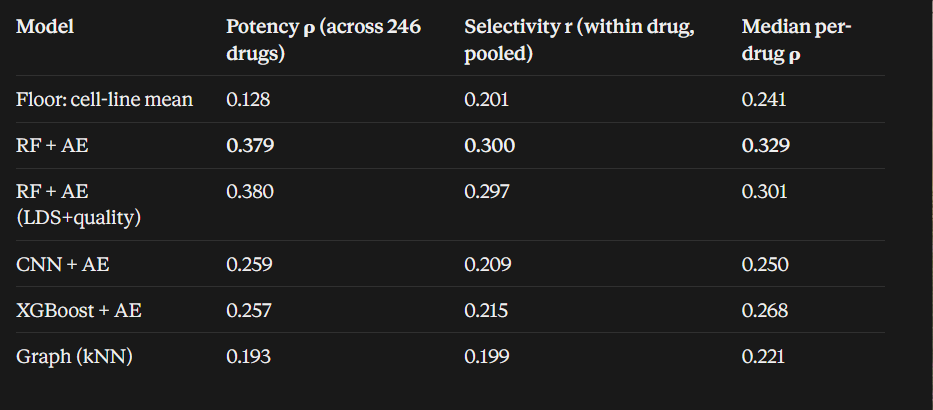

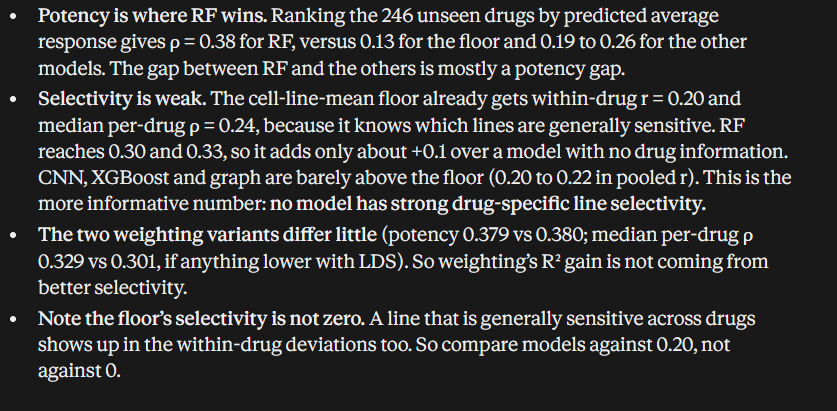

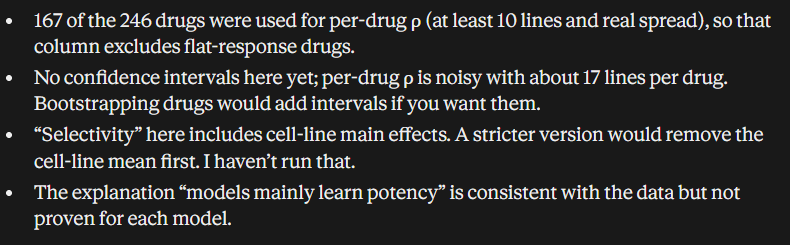